In [159]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [160]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]
imagens= [1, 2, 4, 9, 10, 12, 11, 13,21, 22, 23, 25, 30, 32]

teste = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]
imagensTodas = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in imagens]


IMAGEM = teste

INDEX_IMG = 0 # Imagem a treinar/testar



Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, as consegue separar. O problema não é o valor do limiar, é que o brilho não distingue fundo de peças. Por isso, segmenta-se pela cor, usando a cor do fundo como referência.   

Porque funciona: no fundo azul, B é bastante maior que R e G. Nas peças isso não acontece: vermelha e laranja têm R alto, a verde tem G alto, a amarela tem R e G altos, e a bege/branca/cinzenta tem os três canais parecidos, logo B não ganha por margem. 

EXPLICAR os valores de tolerancia. as sombras baixam nao so o azul mas tbm as outras cores, por isso r e g precisa de ter alguma tolerancia, mas não tanto como o blue, pq o fundo é azul, etc.. 

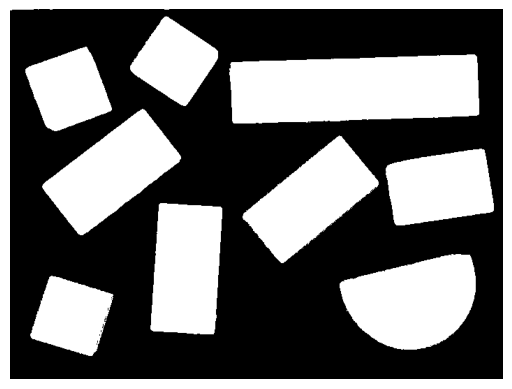

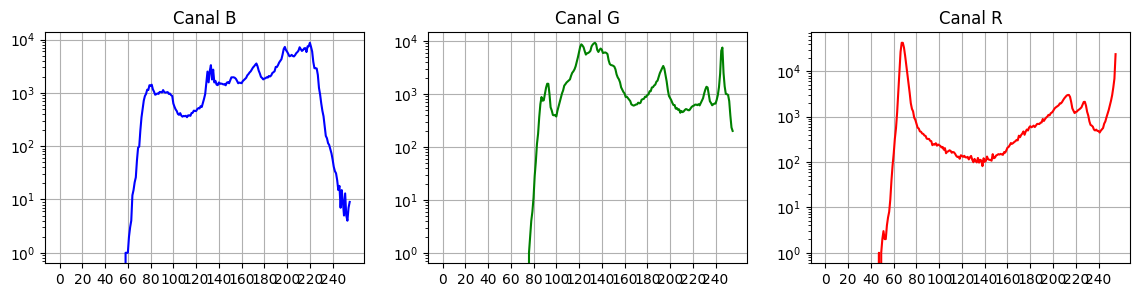

In [161]:
# Binarização


histogramas = []


def pecas(img):

    cor = []
    hists = []
    # cor dominante = bin mais cheio do histograma 3D

    #loop em que se vai ao canal 0,1 e 2 (rgb) e calcula-se um histograma para cada um dos canais. Depois 
    for i in range(3):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        cor.append(np.argmax(hist))#da o valor do canal que tem mais pixeis associados 
        hists.append(hist)
    histogramas.append(hists)

    #os tres canais juntos formam a cor mais dominante, que corresponde ao fundo
    
    b, g, r = cor
    tol_b, tol_g, tol_r = 90, 53, 52

    
    #tolerâncias aplicadas
    min = np.clip([b - tol_b, g - tol_g, r - tol_r], 0, 255)
    max = np.clip([b + tol_b, g + tol_g, r + tol_r], 0, 255)
    fundo = cv2.inRange(img, min, max)

    return 255 - fundo



#para relatorio
def mostraHist(hists):
    cores = ["blue", "green", "red"]
    nomes = ["B", "G", "R"]

    plt.figure(figsize=(14, 3))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.plot(hists[i], color=cores[i])     # hists[i], não hist
        plt.yscale("log")
        plt.xticks(range(0, 256, 20))
        plt.grid(True)
        plt.title("Canal " + nomes[i])
    plt.show()



binarizacao = [pecas(img) for img in imagensTodas]

#mostrar 1 para relatorio
plt.imshow(binarizacao[INDEX_IMG],cmap="gray")
plt.axis("off")
plt.show()

index = 0
for img in binarizacao:
    cv2.imwrite(f'bin{index+1}.jpg', img)
    index += 1

mostraHist(histogramas[0])


Os Operadores Morfológicos limpam a imagem binaria antes da extração dos contornos. Faz-se abertura(erosão -> dilatação) para remover as partes brancas e mais pequenas que nao fazem parte das peças. Faz-se o fecho (dilatação -> erosão) para fechar pequenos buracos, como os reflexos nos pinos do Lego. A abertura vem primeiro para remover o ruído antes de fechar, senão o fecho consolidava os pontos de ruído junto às peças e podia voltar a ligar peças proximas. 

A cross ficava com vários pontinhos brancos onde não existiam peças. O rect era bem aproveitado se todas as peças estivessem direitas mas como não estão os cantos comecaçam a desaparecer e a ficar redondos. Então a ellipse foi a melhor opção, uma vez que não deformou as peças, nem acrescentou ruído extra. 

Pq se aumenta o tamanho do kernel?
1. Erosão: encolhe as regiões brancas, podendo eliminar as mais pequenas.
2. Dilatação: volta a expandir as regiões que sobreviveram à erosão.
Com o kernel anterior de \(7\times7\), algumas manchas de ruído conseguiam sobreviver à erosão. Ao aumentares o kernel para \(22\times22\), a erosão torna-se muito mais agressiva, eliminando irregularidades maiores.

EXPLICAÇÃO DA ORDEM FECHO E DEPOIS ABERTURA:

Porque a abertura e o fecho são assimétricos: cada um age sobre uma coisa diferente.

A abertura (erosão → dilatação) remove o que é branco e mais pequeno que o kernel. Na peça com pinos, o branco entre os buracos são tiras estreitas, bem mais finas que 22 px. A erosão apaga-as por completo e os buracos crescem até se fundirem uns com os outros e com o fundo. A dilatação só consegue expandir o que sobreviveu, e o que foi apagado não volta. Por isso sobrou aquele esqueleto. Para a abertura, a peça cheia de buracos não é um objeto sólido, é um conjunto de tiras finas, e trata-as como ruído.

O fecho (dilatação → erosão) tapa o que é preto e mais pequeno que o kernel. Os buracos dos pinos são pretos e pequenos. A dilatação expande o branco e preenche-os totalmente, e a erosão seguinte devolve o contorno exterior à dimensão original. Os buracos não reaparecem, porque já não há preto no sítio onde estavam para a erosão recuperar.

Com o fecho primeiro, a peça já chega à abertura como uma região sólida com cerca de 55 px de largura (pelo que se vê no teu print), muito mais larga que o kernel de 22 px, e sobrevive intacta. A abertura passa a fazer só o que querias, que é limpar ruído pequeno fora das peças.

Apesar do aumento do kernel, foi necessário filtrar pela área (assegurar um limite de área para as peças), o que permitiu identificar ruído que não era eliminado pela abertura (kernel) e eliminá-lo.  

O carimbo define o que conta como “pequeno”. Com 22 px, a abertura apaga qualquer coisa branca mais estreita que ~22 px, e o fecho tapa buracos pretos até ~22 px. Por isso o tamanho certo depende da resolução da imagem e do tamanho do que queres manter ou remover,

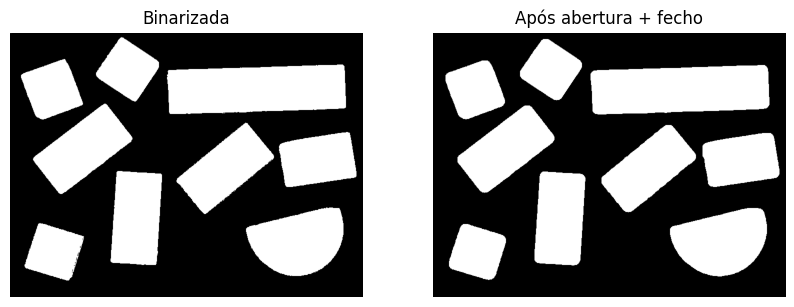

In [162]:
# Operadores Morfológicos

kernel_a = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (22,22)) # elemento estruturante gda abertura
kernel_f= cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)) # do fecho


# O fecho é melhor 

# A função limpar aplica abertura seguida de fecho a uma imagem binária
# Problema: não separam peças muito próximas
def limpar(bin_):

    fecho = cv2.morphologyEx(bin_, cv2.MORPH_CLOSE, kernel_f)   # fecho
    abertura = cv2.morphologyEx(fecho, cv2.MORPH_OPEN, kernel_a)    # abertura

    return abertura


img_limpo = [limpar(b) for b in binarizacao]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(binarizacao[INDEX_IMG], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(img_limpo[INDEX_IMG], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")

indexi = 0
for img in img_limpo:
    cv2.imwrite(f'limpo{indexi+1}.jpg', img)
    indexi += 1

Erodimos 5 vezes porque testámos a partir da função connectedComponents() e a partir do 5 já resultava o número final de peças. pq...(pesquisar potencial motivo). 


PORQUE ESSE TAMANHO DE KERNEL para a erosao

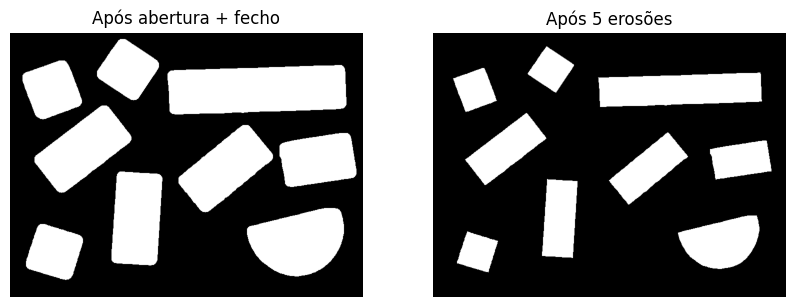

Imagem limpa:  9
Imagem com peças separadas:  9


In [163]:
# Separar peças juntas com Erosão

# A função separar aplica erosão a uma imagem limpa para separar as peças
# o 5 foi escolhido depois de testar com vários valores (célula a seguir)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))

def separar(limpa, it=5):
    return cv2.erode(limpa, kernel, iterations=it) 

img_sep   = [separar(l) for l in img_limpo]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img_limpo[INDEX_IMG], cmap="gray")
ax[0].set_title("Após abertura + fecho")
ax[0].axis("off")

ax[1].imshow(img_sep[INDEX_IMG], cmap="gray")
ax[1].set_title("Após 5 erosões")
ax[1].axis("off")
plt.show()


#para guardar as imgs
index = 0
for img in img_sep:
    cv2.imwrite(f'sep{index+1}.jpg', img)
    index += 1


# ===== Testar a partir da etiquetação =====

resultado_limpo = [cv2.connectedComponents(tl) for tl in img_limpo] # lista de tuplos: (número de objetos, etiquetas)
resultado_sep= [cv2.connectedComponents(ts) for ts in img_sep] 
# [x][0] -> n objetos
# [x][1] -> etiquetas

print("Imagem limpa: ", resultado_limpo[INDEX_IMG][0] - 1) # 0 é o fundo, daí subtraí-se 1
print("Imagem com peças separadas: ", resultado_sep[INDEX_IMG][0] - 1) 

A imagem original tem 4 peças mas duas juntas, e usando a imagem limpa apenas se detetam 3 peças
Na imagem com peças separadas já dá o resultado correto

O connectedComponents devolve as regiões identificadas, mas não fornece diretamente os contornos necessários para o método de classificação que implementaste. Então para a etiquetação utilizamos o findContours, que permite obter os contornos de cada objeto, que são necessários para calcular as medidas utilizadas na classificação.

Número de objetos encontrados:  9


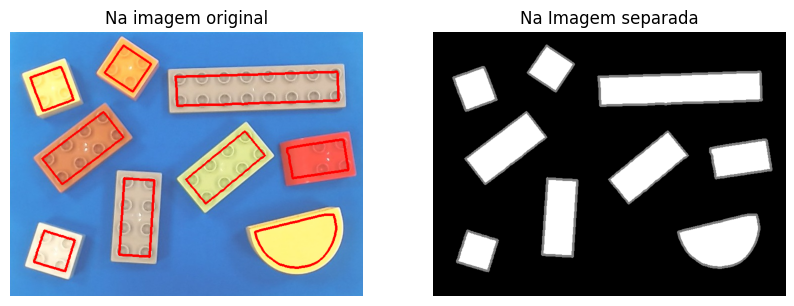

In [164]:
# Etiquetação

# findContours -> devolve uma lista de pontos da fronteira, e cada contorno corresponde a um objeto.
# drawContours desenha esses contornos, ou preenche-os se thickness=-1, o que dá uma máscara por peça.
# Os contornos servem depois para o próximo passo

contornos = [cv2.findContours(ts, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] for ts in img_sep]
# RETR_EXTERNAL apanha só os contornos exteriores
# CHAIN_APPROX_SIMPLE guarda só os pontos finais de cada linha (poupa memória)
# [0] -> só para obter os contornos pq a função devolve um tuplo mas só precisamos do primeiro elemento



contorno = contornos[INDEX_IMG]
print("Número de objetos encontrados: ", len(contorno)) 

org = imagensTodas[INDEX_IMG].copy()
cv2.drawContours(org, contorno, -1, (0, 0, 255), 3)

sep = img_sep[INDEX_IMG].copy()
cv2.drawContours(sep, contorno, -1, 128, 3) # contornos a cinzento

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(org[:, :, ::-1])
ax[0].set_title("Na imagem original")
ax[0].axis("off")

ax[1].imshow(sep, cmap="gray")
ax[1].set_title("Na Imagem separada")
ax[1].axis("off")
plt.show()

Na imagem original os contornos estão mais pequenos porque as erosões diminuiram os tamanhos das peças.

minAreaRect: Melhor escolha. As razões teóricas são 1, 2, 3 e 4, e não dependem da rotação da peça.
contourArea: Boa, como confirmação. Proporcional ao nº de pinos (4, 8, 12, 16), e como a câmara é paralela à mesa e está fixa, a escala é constante
contourArea + minAreaRect: Boa para filtrar ruído. Peças retangulares dão valores próximos de 1, e as outras peças de Lego presentes na imagem ficam abaixo.

In [165]:
margem = 5 * 3 * 2 # número de erosões * raio do elemento estruturante * lados - isto tudo é o númeor de px perdidos nas erosões, numa dimensao (ou w, ou h)
# 5 × 3 = 15 px são o que se perde num lado
# O elemento é uma elipse de 7x7 píxeis, ou seja, tem um centro e 3 píxeis para cada lado (3 + 1 + 3 = 7).
# A largura tem dois lados (esquerdo e direito), por isso perde 2 × 15 = 30 px
# O comprimento também tem dois lados (cima e baixo), por isso também perde 30 px
# Por isso a margem é somada à largura e ao comprimento (*AQUI)


# função que recebe um contorno e devolve as suas medidas num dicionário
def medir(contorno):
    
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    # minAreaRect calcula o menor retângulo, possivelmente rodado, que contém o contorno
    # (cx, cy): o centro do retângulo
    # (w, h): a largura e a altura desse retângulo

    area = cv2.contourArea(contorno) 
    # Área da região dentro do contorno, em píxeis. É a área da peça real (depois da erosão), e não a do retângulo.

    ret = area / (w * h) # retangularidade (sem compensação, é só uma razão de áreas)
    # Retangularidade: área da peça real a dividir pela área do retângulo
    # Se a peça for um retângulo perfeito, os dois valores coincidem e o resultado é 1
    # Se for outra forma, a peça preenche só parte do retângulo e o valor desce (o semicírculo deu cerca de 0,79)
    # Está antes da compensação de propósito: a area do contorno é a erosionada, por isso w * h também tem de ser 
    # Se somasse a margem primeiro, estaria a comparar uma área pequena com um retângulo já “reposto”, 
    # e a razão ficaria errada. Na verdade, a erosão tira o mesmo número de px (30) a cada dimensão, e não uma percentagem. Por isso a razão muda e deixa de dar 1, 2, 3, 4, 
    #o que estragaria as nossas referências para classificar. 

    w += margem # (*AQUI)
    h += margem # (*AQUI)

    maior, menor = max(w, h), min(w, h)
    # minAreaRect pode devolver w como o lado curto ou o comprido, conforme a rotação da peça
    # Com max e min, maior é sempre o lado comprido e menor o lado curto 
    # Assim a razão maior / menor é sempre ≥ 1 e não depende da orientação.

    return {"centro": (cx, cy), "maior": maior, "menor": menor,
            "razao": maior / menor, "area": area, "retangularidade": ret}


for c in contorno:
    m = medir(c)
    print(f"img {INDEX_IMG} | razão {m['razao']:.2f} | área {m['area']:.0f} | ret {m['retangularidade']:.2f}")
    # NECESSÁRIO PERCORRER TODAS DE TREINO PARA ANALISAR MELHOR OS VALORES E TIRAR CONCLUSÕES

img 0 | razão 1.01 | área 4215 | ret 0.95
img 0 | razão 1.56 | área 11861 | ret 0.79
img 0 | razão 2.00 | área 9238 | ret 0.97
img 0 | razão 1.57 | área 6981 | ret 0.95
img 0 | razão 1.94 | área 9554 | ret 0.97
img 0 | razão 1.93 | área 9986 | ret 0.97
img 0 | razão 3.97 | área 18625 | ret 0.96
img 0 | razão 1.05 | área 4664 | ret 0.95
img 0 | razão 1.01 | área 4488 | ret 0.97


Justificar os intervalos das razões

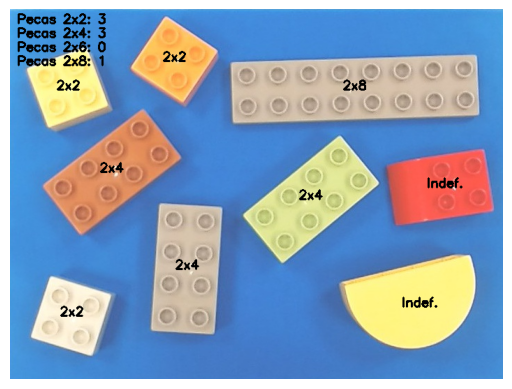

In [166]:
# Classificação

def classificar(m):
    # rejeitar o que não é retangular (semicírculo, outras peças, ruído)
    if m["retangularidade"] < 0.85:
        return None
    r = m["razao"]
    # classificar pela razão, com zonas de rejeição entre as classes
    if 0.85 <= r <= 1.25:
        return "2x2"
    elif 1.75 <= r <= 2.25:
        return "2x4"
    elif 2.6 <= r <= 3.3:
        return "2x6"
    elif 3.5 <= r <= 4.3:
        return "2x8"
    return None   # razão fora das classes (ex.: peça vermelha curva, 1.54)

# Escreve na imagem as peças identificadas
def contar(conts, img_cor):
    contagem = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0}
    saida = img_cor.copy()

    for c in conts:
        m = medir(c) # métricas
        tipo = classificar(m) # classificação

        cx, cy = m["centro"]

        if tipo is None:
            cv2.putText(saida, "Indef.", (int(cx) - 17, int(cy)), # imagem, texto, posição
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) # fonte, tamanho, cor, espessura
            continue

        contagem[tipo] += 1
        
        cv2.putText(saida, tipo, (int(cx) - 17, int(cy)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) 

    # resumo no canto superior esquerdo
    for k, tipo in enumerate(["2x2", "2x4", "2x6", "2x8"]):
        cv2.putText(saida, f"Pecas {tipo}: {contagem[tipo]}", (10, 20 + 20 * k),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return saida

saida = contar(contornos[INDEX_IMG], imagensTodas[INDEX_IMG])
plt.imshow(saida[:, :, ::-1])
plt.axis("off")
plt.show()

a peça vermelha é 2x4 no entanto como está vista de um angulo onde se vê a altura, ao calcular a área ficaria fora do intervalo esperado ou de qualquer outro intervalo sendo o mais correto porque se não deteta que é 2x4 mais vale ser rejeitada do que mal classificada.